# Customers Like You: analysis

Runs top to bottom on the files written by `python build_matrix.py`. The model code is in
[recommender.py](recommender.py), so this notebook calls it and explains the results.
Customer IDs are never loaded: customers appear only as row indices (R4).

## Section 3: PCA or SVD?

The ML1 decision was written before anything was fitted, in [method_decision.md](method_decision.md):
**Truncated SVD is the main model and PCA is the comparison.** This section runs both on the same
matrix with the same k, fills in the ML5 table with our own numbers, and checks the predictions
made in ML1. The filled table and findings are written to [reports/pca_vs_svd.md](reports/pca_vs_svd.md).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from sklearn.decomposition import PCA, TruncatedSVD

import recommender as rec
from build_matrix import md_table

K = 50  # the same k for both methods; the final k is chosen in ML2
K_VALUES = [10, 20, 50, 100, 200]
METHODS = {"svd": "Truncated SVD", "pca": "PCA"}
FIGURES, REPORTS = Path("figures"), Path("reports")
FIGURES.mkdir(exist_ok=True)

A, products, holdout = rec.load()
test_customers = np.sort(holdout["customer_idx"].unique())
buyers = np.diff(A.tocsc().indptr)          # training customers per product
volume = np.asarray(A.sum(axis=1)).ravel()  # each customer's total log(1 + units)
print(f"A: {A.shape[0]:,} customers x {A.shape[1]:,} products, {A.nnz:,} non-zeros")
print(f"Held out: {len(holdout):,} purchases by {len(test_customers):,} test customers")

A: 5,456 customers x 3,680 products, 411,136 non-zeros
Held out: 44,552 purchases by 1,903 test customers


In [2]:
# Chart style: validated categorical slots 1-2 (blue, orange) on the light chart surface
COLORS = {"svd": "#2a78d6", "pca": "#eb6834"}
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

### 3.1 Fit both methods on the same matrix

Both use the same ARPACK solver and seed, so any difference comes from centring alone. PCA runs on
the sparse matrix: scikit-learn centres it implicitly, without storing the centred copy. Times are
the best of 3 runs. Peak memory is what the fit allocates (measured with `tracemalloc`), not
counting the 5 MB input. The randomized SVD solver, scikit-learn's default, is shown for reference.

In [3]:
models, cost = {}, {}
for m in METHODS:
    models[m], seconds, peak = rec.measure(lambda: rec.fit(m, A, K))
    cost[METHODS[m]] = {"fit seconds": seconds, "peak MB during fit": peak,
                        "stored factors MB": rec.factor_size_mb(models[m], A)}
randomized, seconds, peak = rec.measure(
    lambda: TruncatedSVD(n_components=K, algorithm="randomized", random_state=rec.SEED).fit(A))
cost["Truncated SVD, randomized solver"] = {"fit seconds": seconds, "peak MB during fit": peak,
                                            "stored factors MB": rec.factor_size_mb(randomized, A)}
print(f"Relative reconstruction error at k = {K}: ARPACK "
      f"{rec.compression_loss(models['svd'], A)['relative_error']:.4f}, "
      f"randomized {rec.compression_loss(randomized, A)['relative_error']:.4f}")
pd.DataFrame(cost).T.round(2)

Relative reconstruction error at k = 50: ARPACK 0.7883, randomized 0.7889


,fit seconds,peak MB during fit,stored factors MB
Truncated SVD,0.21,12.62,3.65
PCA,0.16,7.73,3.68
"Truncated SVD, randomized solver",0.42,9.68,3.65


**What centring costs.** PCA subtracts each product's average from its column. Every kept product
has at least 10 buyers, so every average is above zero and every zero cell becomes a small
negative number. Implicit centring avoids storing that matrix. Centring it ourselves, which is
what PCA means on paper, has the cost shown below.

In [4]:
mean = models["pca"].mean_
n_cells = A.shape[0] * A.shape[1]
print(f"Product averages: mean {mean.mean():.4f}, largest {mean.max():.4f}; all positive: {(mean > 0).all()}")
print(f"Before centring {A.nnz / n_cells:.2%} of the {n_cells:,} cells are non-zero; after centring none "
      f"are zero, which is {n_cells * 8 / rec.MB:.1f} MB stored densely")
_, dense_seconds, dense_peak = rec.measure(
    lambda: PCA(n_components=K, svd_solver="arpack", random_state=rec.SEED).fit(A.toarray()), repeats=1)
print(f"PCA on the explicitly centred dense matrix: {dense_seconds:.2f} s, peak {dense_peak:.0f} MB")

Product averages: mean 0.0434, largest 0.7357; all positive: True
Before centring 2.05% of the 20,078,080 cells are non-zero; after centring none are zero, which is 160.6 MB stored densely


PCA on the explicitly centred dense matrix: 1.37 s, peak 490 MB


### 3.2 What is lost by compressing

Two numbers for each k:

- **Relative reconstruction error**, ||A − A_k|| / ||A||. This is the same measure for both methods;
  PCA's A_k adds the averages back.
- **Share kept**, in each method's own language. For SVD it is the share of the whole matrix kept,
  ||A_k||² / ||A||². For PCA it is the explained variance ratio, the share of the variation *around
  the average customer* that is kept.

In [5]:
loss = pd.DataFrame([{"k": k, "method": METHODS[m], **rec.compression_loss(rec.fit(m, A, k), A)}
                     for k in K_VALUES for m in METHODS])
# PCA's share kept is exactly its explained variance ratio
assert np.isclose(loss.query("k == @K and method == 'PCA'")["share_kept"].item(),
                  models["pca"].explained_variance_ratio_.sum())
loss.pivot(index="k", columns="method").round(4)

relative_error               share_kept              
method            PCA Truncated SVD        PCA Truncated SVD
k                                                           
10             0.8752        0.8756     0.1995        0.2333
20             0.8450        0.8453     0.2538        0.2855
50             0.7882        0.7883     0.3508        0.3785
100            0.7257        0.7258     0.4496        0.4732
200            0.6369        0.6370     0.5760        0.5942

The reconstruction error is the same for both methods to three decimals. The share kept differs
only because the two methods divide by different totals: PCA's total leaves out the average
customer. The cell below shows why that changes so little here.

In [6]:
average_share = A.shape[0] * mean @ mean / sp.linalg.norm(A) ** 2
svd_1 = models["svd"].components_[0]
align = np.abs(np.sum(models["svd"].components_ * models["pca"].components_, axis=1))
subspace = np.linalg.svd(models["svd"].components_ @ models["pca"].components_.T, compute_uv=False).min()
print(f"The average customer is {average_share:.1%} of the matrix (share of ||A||^2)")
print(f"Cosine between SVD component 1 and the average customer: {abs(svd_1 @ mean) / np.linalg.norm(mean):.3f}")
print(f"|cosine| between the methods, components 1-5: {np.round(align[:5], 3)}")
print(f"Smallest cosine between the two {K}-dimensional subspaces: {subspace:.3f}")

The average customer is 4.3% of the matrix (share of ||A||^2)
Cosine between SVD component 1 and the average customer: 0.986
|cosine| between the methods, components 1-5: [0.996 0.996 0.998 0.998 0.985]
Smallest cosine between the two 50-dimensional subspaces: 0.982


The average customer buys almost nothing of any one product, because the matrix is 98% zeros. The
averages PCA removes are therefore tiny, and SVD's first component already points almost exactly
along them. Centring moves every zero by a few hundredths. The directions both methods find are
the same, component by component and as a whole subspace.

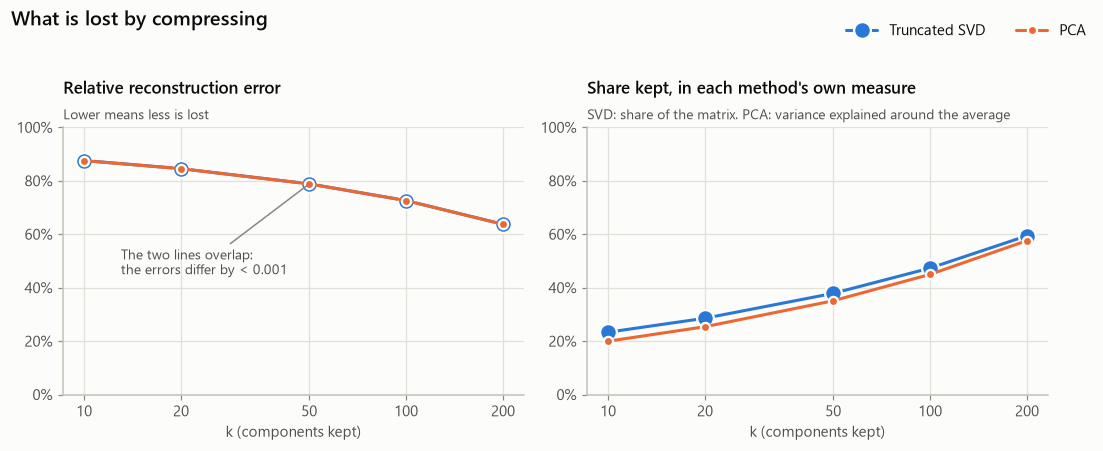

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharex=True)
panels = [("relative_error", "Relative reconstruction error", "Lower means less is lost"),
          ("share_kept", "Share kept, in each method's own measure",
           "SVD: share of the matrix. PCA: variance explained around the average")]
for ax, (column, title, subtitle) in zip(axes, panels):
    for m, name in METHODS.items():  # SVD drawn larger underneath, so it shows where the lines overlap
        d = loss[loss["method"] == name]
        ax.plot(d["k"], d[column], color=COLORS[m], marker="o", markersize=11 if m == "svd" else 6,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=name)
    ax.set_title(title, pad=22)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, color=INK_2, fontsize=9)
    ax.set_xscale("log")
    ax.set_xticks(K_VALUES, [str(k) for k in K_VALUES])
    ax.minorticks_off()
    ax.set_xlabel("k (components kept)")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 1)
axes[0].annotate("The two lines overlap:\nthe errors differ by < 0.001", xy=(50, loss.query("k == 50")["relative_error"].mean()),
                 xytext=(13, 0.45), color=INK_2, fontsize=9, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 1})
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(1, 1.04))
fig.suptitle("What is lost by compressing", x=0.01, ha="left", y=1.04, fontsize=13, fontweight="semibold")
fig.tight_layout()
fig.savefig(FIGURES / "compression_loss.png")
plt.show()

### 3.3 What component 1 represents

The sign of a component is arbitrary, so each is flipped to point towards "buys more". We look at
the product weights and at how the customer scores relate to how much each customer buys.

In [8]:
comp1 = {}
for m, model in models.items():
    sign = np.sign(model.components_[0].sum())
    weights = model.components_[0] * sign
    scores = model.transform(A)[:, 0] * sign
    comp1[m] = {"weights": weights, "positive": (weights > 0).mean(),
                "r_popularity": np.corrcoef(weights, buyers)[0, 1], "r_volume": np.corrcoef(scores, volume)[0, 1]}
pd.DataFrame({METHODS[m]: {"products with a positive weight": f"{c['positive']:.1%}",
                           "correlation of product weight with its number of buyers": f"{c['r_popularity']:.2f}",
                           "correlation of customer score with their volume": f"{c['r_volume']:.2f}"}
              for m, c in comp1.items()})

,Truncated SVD,PCA
products with a positive weight,100.0%,99.8%
correlation of product weight with its number of buyers,0.94,0.91
correlation of customer score with their volume,0.97,0.97


In [9]:
def ends(weights, n=6):
    order = np.argsort(-weights)
    return pd.DataFrame({"highest weight": products["Description"].iloc[order[:n]].to_numpy(),
                         "lowest weight": products["Description"].iloc[order[::-1][:n]].to_numpy()},
                        index=pd.RangeIndex(1, n + 1, name="rank"))

for label, weights in [("SVD component 1", comp1["svd"]["weights"]), ("PCA component 1", comp1["pca"]["weights"]),
                       ("PCA component 2", models["pca"].components_[1])]:
    display(Markdown(f"**{label}**"), ends(weights))

**SVD component 1**

,highest weight,lowest weight
rank,,
1,PACK OF 72 RETRO SPOT CAKE CASES,AMBER GLASS TASSLE BAG CHARM
2,WHITE HANGING HEART T-LIGHT HOLDER,SILVER LARIAT 40CM
3,JUMBO BAG RED RETROSPOT,PINK SQUARE COMPACT MIRROR
4,LUNCH BAG RED RETROSPOT,PURPLE GLASS TASSLE BAG CHARM
5,60 TEATIME FAIRY CAKE CASES,S/6 PAPER BOXES BLOSSOM IMAGES
6,ASSORTED COLOUR BIRD ORNAMENT,FOUR PICTURE WHITE GLASS FRAME


**PCA component 1**

,highest weight,lowest weight
rank,,
1,PACK OF 72 RETRO SPOT CAKE CASES,AMBER GLASS TASSLE BAG CHARM
2,JUMBO BAG RED RETROSPOT,PURPLE GLASS TASSLE BAG CHARM
3,LUNCH BAG RED RETROSPOT,WHITE HYDRANGEA ART FLOWER
4,WHITE HANGING HEART T-LIGHT HOLDER,BROWN ANTIQUE CUBE CANDLE
5,60 TEATIME FAIRY CAKE CASES,SILVER LARIAT 40CM
6,LUNCH BAG SPACEBOY DESIGN,PINK SQUARE COMPACT MIRROR


**PCA component 2**

,highest weight,lowest weight
rank,,
1,WHITE HANGING HEART T-LIGHT HOLDER,PLASTERS IN TIN SPACEBOY
2,HEART OF WICKER SMALL,PACK OF 72 RETRO SPOT CAKE CASES
3,HEART OF WICKER LARGE,MINI PAINT SET VINTAGE
4,PLEASE ONE PERSON METAL SIGN,ROUND SNACK BOXES SET OF4 WOODLAND
5,ASSORTED COLOUR BIRD ORNAMENT,SPACEBOY LUNCH BOX
6,RED HANGING HEART T-LIGHT HOLDER,LUNCH BAG SPACEBOY DESIGN


**Component 1 is "overall buying" in both methods.** Every product (SVD), or nearly every product
(PCA), weighs in with the same sign. The heaviest weights go to the best sellers (retro-spot cake
cases, the white hanging heart, jumbo bags), the lightest to rarely bought jewellery and glassware.
A customer's score on it follows how much they buy. PCA removes the average customer, but not the
differences in *how much* customers buy, and those differences are still the biggest variation.
The first true contrast between kinds of shops is **PCA component 2**: home decoration (hanging
hearts, wicker hearts, metal signs) against children's and lunch items (Spaceboy lunch boxes,
plasters in tins, snack boxes). SVD's component 2 is the same direction.

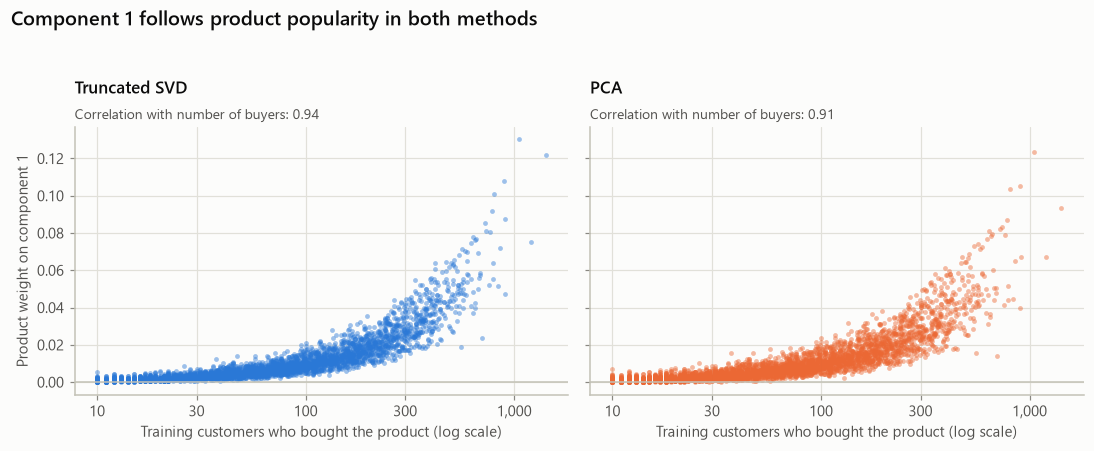

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, (m, name) in zip(axes, METHODS.items()):
    ax.scatter(buyers, comp1[m]["weights"], s=10, color=COLORS[m], alpha=0.45, linewidths=0)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_xscale("log")
    ax.set_xticks([10, 30, 100, 300, 1000], ["10", "30", "100", "300", "1,000"])
    ax.minorticks_off()
    ax.set_title(f"{name}", pad=22)
    ax.text(0, 1.03, f"Correlation with number of buyers: {comp1[m]['r_popularity']:.2f}",
            transform=ax.transAxes, color=INK_2, fontsize=9)
    ax.set_xlabel("Training customers who bought the product (log scale)")
axes[0].set_ylabel("Product weight on component 1")
fig.suptitle("Component 1 follows product popularity in both methods", x=0.01, ha="left", y=1.04,
             fontsize=13, fontweight="semibold")
fig.tight_layout()
fig.savefig(FIGURES / "component1_popularity.png")
plt.show()

### 3.4 What it means for recommendations

First, the "customers who bought this also bought" box for the best seller, using ML3's rule: the
10 products whose factor vectors have the highest cosine similarity.

In [11]:
similar = {m: rec.similar_products(model.components_.T) for m, model in models.items()}
best_seller = int(np.argmax(buyers))
print(f"Customers who bought {products['Description'].iloc[best_seller]} also bought:")
display(pd.DataFrame({METHODS[m]: products["Description"].iloc[similar[m][best_seller]].to_numpy() for m in METHODS},
                     index=pd.RangeIndex(1, 11, name="rank")))
overlap = np.mean([len(set(a) & set(b)) for a, b in zip(similar["svd"], similar["pca"])]) / 10
print(f"Across all {A.shape[1]:,} products, the SVD and PCA top-10 lists share {overlap:.0%} of their products")

Customers who bought WHITE HANGING HEART T-LIGHT HOLDER also bought:


,Truncated SVD,PCA
rank,,
1,RED HANGING HEART T-LIGHT HOLDER,RED HANGING HEART T-LIGHT HOLDER
2,CANDLEHOLDER PINK HANGING HEART,CANDLEHOLDER PINK HANGING HEART
3,RED HANGING METAL STAR TLIGHT HLDR,RED HANGING METAL STAR TLIGHT HLDR
4,COLOUR GLASS. STAR T-LIGHT HOLDER,COLOUR GLASS. STAR T-LIGHT HOLDER
5,CREAM HEART CARD HOLDER,CREAM HEART CARD HOLDER
6,JAZZ HEARTS SPIRAL NOTEPAD,JAZZ HEARTS SPIRAL NOTEPAD
7,BLUE GINGHAM ROSE QUILT,BLUE GINGHAM ROSE QUILT
8,MOSAIC GLASS BALL CANDLEHOLDER,MOSAIC GLASS BALL CANDLEHOLDER
9,SCALLOP SHELL SOAP DISH,WHITE METAL LANTERN


Across all 3,680 products, the SVD and PCA top-10 lists share 96% of their products


**Hit rate at 10** is the share of test customers with at least one held-out purchase in their
top 10, never counting products they already bought. Two scoring rules are compared on the same
factors:

- **Cosine similarity**, ML3 as the brief writes it: a product's score is its summed cosine
  similarity to what the customer bought.
- **Rebuilt row**, the same sum with dot products instead of cosines. This equals scoring with the
  customer's row of A_k. A product's vector length grows with how much it sells, and cosine throws
  that length away.

The baseline recommends the 10 products with the most training buyers that the customer has not
bought (R3).
*Which rule ships is an ML3 decision, and it should be made on a validation split cut from the
training period, not on these test numbers.*

In [12]:
def evaluate(score):
    return rec.hit_rate(rec.recommend(A, score, customers=test_customers), test_customers, holdout)

COSINE, REBUILT = "cosine similarity (ML3 as written)", "rebuilt row (dot products)"
baseline = evaluate(rec.popularity_scorer(A))
hits = pd.DataFrame({METHODS[m]: {COSINE: evaluate(rec.similarity_scorer(model.components_.T)),
                                  REBUILT: evaluate(rec.reconstruction_scorer(model)),
                                  "best-seller baseline": baseline}
                     for m, model in models.items()})
hits.map("{:.1%}".format)

,Truncated SVD,PCA
cosine similarity (ML3 as written),21.2%,21.2%
rebuilt row (dot products),37.1%,37.7%
best-seller baseline,26.9%,26.9%


**What the average customer adds.** PCA's rebuilt row is the average customer plus that
customer's deviations from it. Splitting the two shows how much the removed average is worth.

In [13]:
V = models["pca"].components_.T
average_effect = pd.Series({
    "PCA rebuilt row (average + deviations)": hits.loc[REBUILT, "PCA"],
    "deviations only (average dropped)": evaluate(lambda rows: (rows @ V - mean @ V) @ V.T),
    "average customer only": evaluate(lambda rows: np.tile(mean, (rows.shape[0], 1))),
})
average_effect.map("{:.1%}".format)

PCA rebuilt row (average + deviations)    37.7%
deviations only (average dropped)         35.2%
average customer only                     21.2%
dtype: str

In [14]:
score_seconds = {}
for m, model in models.items():
    _, score_seconds[m], _ = rec.measure(lambda: rec.recommend(A, rec.similarity_scorer(model.components_.T)), repeats=1)
    print(f"{METHODS[m]}: top 10 for all {A.shape[0]:,} customers in {score_seconds[m]:.2f} s")

Truncated SVD: top 10 for all 5,456 customers in 0.23 s


PCA: top 10 for all 5,456 customers in 0.23 s


### 3.5 Comparison table (ML5) and the ML1 predictions

The cell below fills in the brief's table, checks each ML1 prediction against the numbers, and
writes both to [reports/pca_vs_svd.md](reports/pca_vs_svd.md).

In [15]:
pct = "{:.1%}".format
svd_loss, pca_loss = rec.compression_loss(models["svd"], A), rec.compression_loss(models["pca"], A)
c_svd, c_pca, h = cost["Truncated SVD"], cost["PCA"], hits
table = pd.DataFrame([
    ("k used", K, K),
    ("Fit time (seconds)", f"{c_pca['fit seconds']:.2f}", f"{c_svd['fit seconds']:.2f}"),
    ("Peak memory during fit (MB)",
     f"{c_pca['peak MB during fit']:.1f} with implicit centring; {dense_peak:.0f} if centred explicitly",
     f"{c_svd['peak MB during fit']:.1f}"),
    ("Size of stored factors (MB)", f"{c_pca['stored factors MB']:.2f} (factors + {A.shape[1]:,} product averages)",
     f"{c_svd['stored factors MB']:.2f}"),
    ("Variance explained or relative reconstruction error",
     f"{pct(pca_loss['share_kept'])} of variance explained; relative error {pca_loss['relative_error']:.3f}",
     f"Relative error {svd_loss['relative_error']:.3f} (keeps {pct(svd_loss['share_kept'])} of the matrix)"),
    ("Hit rate at 10 on held-out purchases",
     f"{pct(h.loc[COSINE, 'PCA'])} cosine; {pct(h.loc[REBUILT, 'PCA'])} rebuilt row",
     f"{pct(h.loc[COSINE, 'Truncated SVD'])} cosine; {pct(h.loc[REBUILT, 'Truncated SVD'])} rebuilt row"),
    ("Best-seller baseline hit rate at 10", pct(baseline), pct(baseline)),
    ("What component 1 represents, in words",
     f"Also overall buying, measured from the average customer: {comp1['pca']['positive']:.1%} of products "
     f"weigh positively (correlation with buyers {comp1['pca']['r_popularity']:.2f}). The first contrast between "
     "kinds of shops is component 2: home decoration against children's and lunch items.",
     f"Overall buying: every product weighs positively, more for popular products (correlation with buyers "
     f"{comp1['svd']['r_popularity']:.2f}); a customer's score follows how much they buy "
     f"(correlation {comp1['svd']['r_volume']:.2f})."),
    (f"Top 10 for all {A.shape[0]:,} customers (seconds)", f"{score_seconds['pca']:.2f}", f"{score_seconds['svd']:.2f}"),
], columns=["Measure", "PCA", "Truncated SVD"])

held = lambda ok: "Held" if ok else "Wrong"
lead = max(h.loc[s, "PCA"] - h.loc[s, "Truncated SVD"] for s in (COSINE, REBUILT))
beats = lambda s: min(h.loc[s]) > baseline
predictions = pd.DataFrame([
    ("SVD fits at least as fast as PCA and needs less memory",
     f"{c_svd['fit seconds']:.2f} s vs {c_pca['fit seconds']:.2f} s; "
     f"{c_svd['peak MB during fit']:.1f} MB vs {c_pca['peak MB during fit']:.1f} MB",
     held(c_svd["fit seconds"] <= 1.1 * c_pca["fit seconds"] and c_svd["peak MB during fit"] < c_pca["peak MB during fit"])),
    ("Centring explicitly needs at least 160 MB", f"Peak {dense_peak:.0f} MB", held(dense_peak >= 160)),
    ("SVD component 1: one sign for every product, follows popularity",
     f"{comp1['svd']['positive']:.0%} positive; correlation {comp1['svd']['r_popularity']:.2f}",
     held(comp1["svd"]["positive"] == 1 and comp1["svd"]["r_popularity"] > 0.8)),
    ("PCA component 1: mixed signs, a contrast between two groups",
     f"{comp1['pca']['positive']:.1%} positive; correlation {comp1['pca']['r_popularity']:.2f}",
     held(comp1["pca"]["positive"] < 0.9)),
    ("Stored factors about 3.7 MB for both",
     f"{c_svd['stored factors MB']:.2f} MB vs {c_pca['stored factors MB']:.2f} MB",
     held(abs(c_svd["stored factors MB"] - 3.7) < 0.2 and abs(c_pca["stored factors MB"] - 3.7) < 0.2)),
    ("SVD's hit rate at least as high as PCA's",
     f"Cosine {pct(h.loc[COSINE, 'Truncated SVD'])} vs {pct(h.loc[COSINE, 'PCA'])}; rebuilt row "
     f"{pct(h.loc[REBUILT, 'Truncated SVD'])} vs {pct(h.loc[REBUILT, 'PCA'])}",
     f"Cosine: {held(h.loc[COSINE, 'Truncated SVD'] >= h.loc[COSINE, 'PCA'])}; "
     f"rebuilt row: {held(h.loc[REBUILT, 'Truncated SVD'] >= h.loc[REBUILT, 'PCA'])}"),
    ("Both methods beat the best-seller baseline", f"Baseline {pct(baseline)}",
     f"Cosine: {held(beats(COSINE))}; rebuilt row: {held(beats(REBUILT))}"),
    ("Decision rule: switch to PCA if its hit rate is at least 1 point higher",
     f"PCA's largest lead: {lead * 100:+.1f} points",
     "Switch to PCA" if lead >= 0.01 else "Decision stands: Truncated SVD"),
], columns=["ML1 prediction", "Result", "Verdict"])
display(table, predictions)

,Measure,PCA,Truncated SVD
0,k used,50,50
1,Fit time (seconds),0.16,0.21
2,Peak memory during fit (MB),7.7 with implicit centring; 490 if centred exp...,12.6
3,Size of stored factors (MB),"3.68 (factors + 3,680 product averages)",3.65
4,Variance explained or relative reconstruction ...,35.1% of variance explained; relative error 0.788,Relative error 0.788 (keeps 37.9% of the matrix)
5,Hit rate at 10 on held-out purchases,21.2% cosine; 37.7% rebuilt row,21.2% cosine; 37.1% rebuilt row
6,Best-seller baseline hit rate at 10,26.9%,26.9%
7,"What component 1 represents, in words","Also overall buying, measured from the average...",Overall buying: every product weighs positivel...
8,"Top 10 for all 5,456 customers (seconds)",0.23,0.23


,ML1 prediction,Result,Verdict
0,SVD fits at least as fast as PCA and needs les...,0.21 s vs 0.16 s; 12.6 MB vs 7.7 MB,Wrong
1,Centring explicitly needs at least 160 MB,Peak 490 MB,Held
2,"SVD component 1: one sign for every product, f...",100% positive; correlation 0.94,Held
3,"PCA component 1: mixed signs, a contrast betwe...",99.8% positive; correlation 0.91,Wrong
4,Stored factors about 3.7 MB for both,3.65 MB vs 3.68 MB,Held
5,SVD's hit rate at least as high as PCA's,Cosine 21.2% vs 21.2%; rebuilt row 37.1% vs 37.7%,Cosine: Held; rebuilt row: Wrong
6,Both methods beat the best-seller baseline,Baseline 26.9%,Cosine: Wrong; rebuilt row: Held
7,Decision rule: switch to PCA if its hit rate i...,PCA's largest lead: +0.6 points,Decision stands: Truncated SVD


In [16]:
report = f"""# PCA vs Truncated SVD (ML5)

Generated by `analysis.ipynb` (Section 3). Both methods were fitted on the training matrix
(`matrix_log1p.npz`, {A.shape[0]:,} customers x {A.shape[1]:,} products) with k = {K}, the same ARPACK
solver and seed {rec.SEED}. The decision being tested was written before fitting:
[method_decision.md](../method_decision.md).

## Comparison table

{md_table(table)}

Fit time is the best of 3 runs. Peak memory is what the fit allocates (`tracemalloc`), not counting
the 5.0 MB input matrix. Hit rate at 10 is the share of the {len(test_customers):,} test customers with
at least one held-out purchase in their top 10. "Cosine" is ML3's rule; "rebuilt row" scores with the
customer's row of A_k (dot products instead of cosines).

## What our numbers show

1. **On this matrix, PCA and SVD give practically the same model.** The average customer that PCA
   removes is only {average_share:.1%} of the matrix: centring shifts every zero by
   {mean.mean():.3f} on average. The reconstruction errors agree to three decimals
   ({svd_loss['relative_error']:.3f} vs {pca_loss['relative_error']:.3f}). The first five
   components point the same way (cosine at least {align[:5].min():.3f}), and the two {K}-dimensional
   subspaces agree to {subspace:.3f}. The "also bought" lists share {overlap:.0%} of their products.
2. **The headline numbers differ only because they divide by different totals.** "Keeps
   {pct(svd_loss['share_kept'])} of the matrix" (SVD) and "explains {pct(pca_loss['share_kept'])} of
   the variance" (PCA) describe the same fit. PCA's total leaves out the average customer.
3. **Centring is costly only if it is done by hand.** scikit-learn's implicit centring keeps PCA as
   cheap as SVD ({c_pca['fit seconds']:.2f} s against {c_svd['fit seconds']:.2f} s). Centring the
   matrix explicitly makes every one of its {n_cells:,} cells non-zero and pushes peak memory to
   {dense_peak:.0f} MB.
4. **Component 1 is overall buying in both methods.** Removing the average does not remove the
   differences in how much customers buy, and those are the biggest variation. The first contrast
   between kinds of shops (home decoration against children's and lunch items) is component 2 in both.
5. **Cosine scoring loses to best sellers; the rebuilt row beats them.** With ML3's cosine rule, SVD hits
   {pct(h.loc[COSINE, 'Truncated SVD'])} and PCA {pct(h.loc[COSINE, 'PCA'])}, against the baseline's
   {pct(baseline)}. Normalising each product vector to length 1 throws away how much a product sells,
   which is exactly the signal best sellers use. Keeping it (rebuilt row) gives
   {pct(h.loc[REBUILT, 'Truncated SVD'])} (SVD) and {pct(h.loc[REBUILT, 'PCA'])} (PCA). In PCA's rebuilt
   row, the removed average is worth {(hits.loc[REBUILT, 'PCA'] - average_effect.iloc[1]) * 100:.1f} points:
   it scores {pct(average_effect.iloc[1])} without it. The scoring rule should be chosen in ML3 on a
   validation split, not on these test numbers.
6. **Decision: Truncated SVD stays.** By the rule written in ML1, PCA's largest lead is
   {lead * 100:+.1f} points, under the 1-point bar. SVD works on the sparse matrix as it is, needs no
   averages stored, and its error is the "what we lose" number for the memo.

## ML1 predictions against the results

{md_table(predictions)}

## Figures

![What is lost by compressing](../figures/compression_loss.png)

![Component 1 against product popularity](../figures/component1_popularity.png)
"""
(REPORTS / "pca_vs_svd.md").write_text(report, encoding="utf-8")
print(f"wrote {REPORTS / 'pca_vs_svd.md'}")

wrote reports\pca_vs_svd.md
